In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# 1. Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define models
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

gb_model = GradientBoostingClassifier(
    random_state=42
)

# 4. Train models
rf_model.fit(X_train, y_train)
gb_model.fit(X_train, y_train)

# 5. Predictions
rf_pred = rf_model.predict(X_test)
gb_pred = gb_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("Gradient Boosting Accuracy:", accuracy_score(y_test, gb_pred))

# 6. Feature importance dataframes
rf_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_model.feature_importances_
}).sort_values(by="importance", ascending=False)

gb_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": gb_model.feature_importances_
}).sort_values(by="importance", ascending=False)

print("\nRandom Forest Top 10 Features")
print(rf_importance.head(10))

print("\nGradient Boosting Top 10 Features")
print(gb_importance.head(10))

Random Forest Accuracy: 0.956140350877193
Gradient Boosting Accuracy: 0.956140350877193

Random Forest Top 10 Features
                 feature  importance
22       worst perimeter    0.133100
23            worst area    0.128052
27  worst concave points    0.108107
7    mean concave points    0.094414
20          worst radius    0.090639
0            mean radius    0.058662
2         mean perimeter    0.055242
3              mean area    0.049938
6         mean concavity    0.046207
26       worst concavity    0.035357

Gradient Boosting Top 10 Features
                 feature  importance
20          worst radius    0.435500
22       worst perimeter    0.271483
27  worst concave points    0.106549
21         worst texture    0.052638
7    mean concave points    0.030458
11         texture error    0.026927
23            worst area    0.022313
26       worst concavity    0.010819
24      worst smoothness    0.010706
13            area error    0.005348


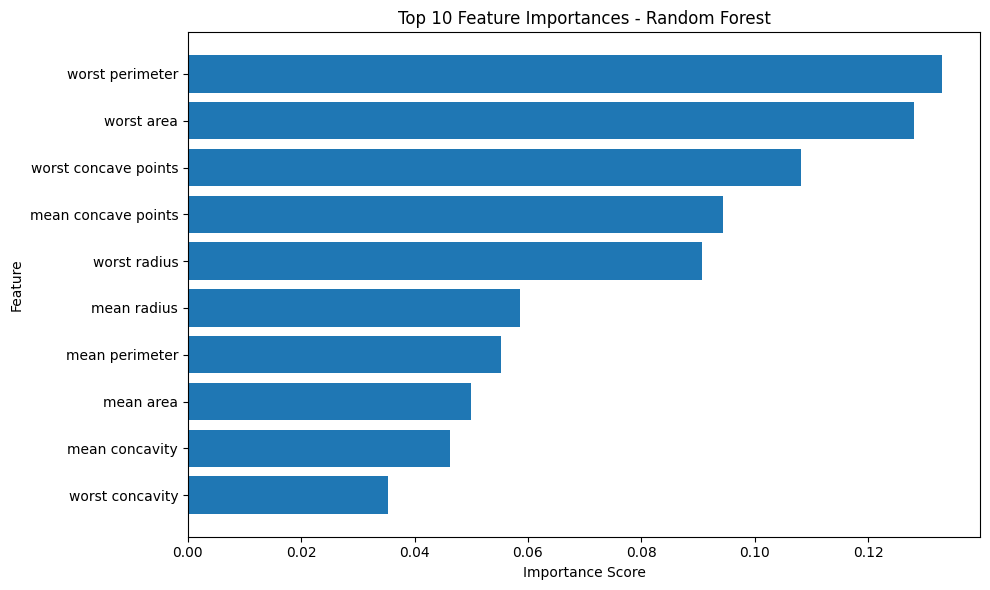

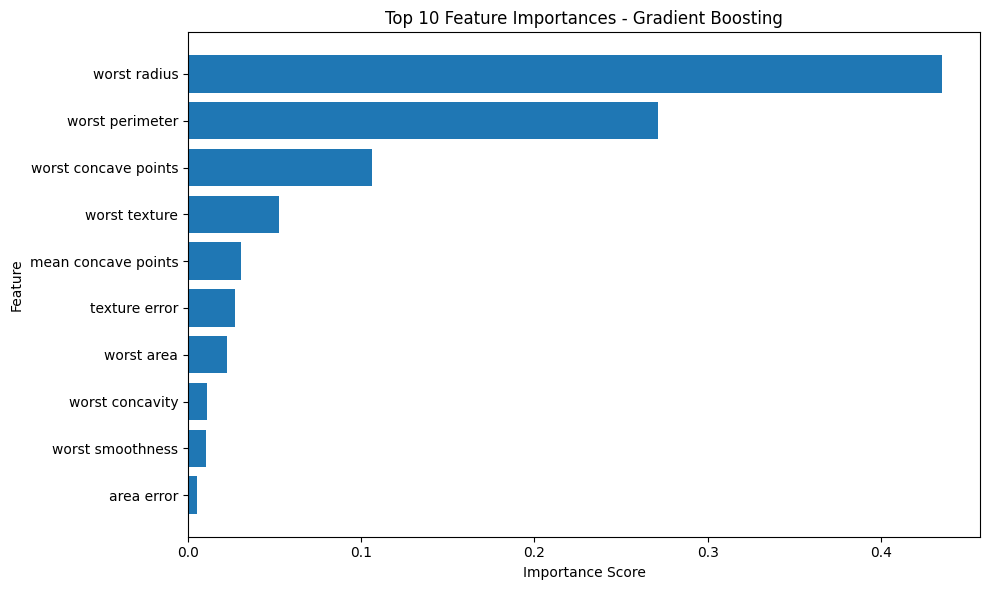

In [ ]:
# 7. Plot Random Forest feature importance
top_n = 10

plt.figure(figsize=(10, 6))
plt.barh(
    rf_importance.head(top_n)["feature"][::-1],
    rf_importance.head(top_n)["importance"][::-1]
)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Random Forest")
plt.tight_layout()
plt.savefig("figures/random_forest_feature_importance.png", dpi=300)
plt.show()


# 8. Plot Gradient Boosting feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    gb_importance.head(top_n)["feature"][::-1],
    gb_importance.head(top_n)["importance"][::-1]
)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Gradient Boosting")
plt.tight_layout()
plt.savefig("figures/gradient_boosting_feature_importance.png", dpi=300)
plt.show()

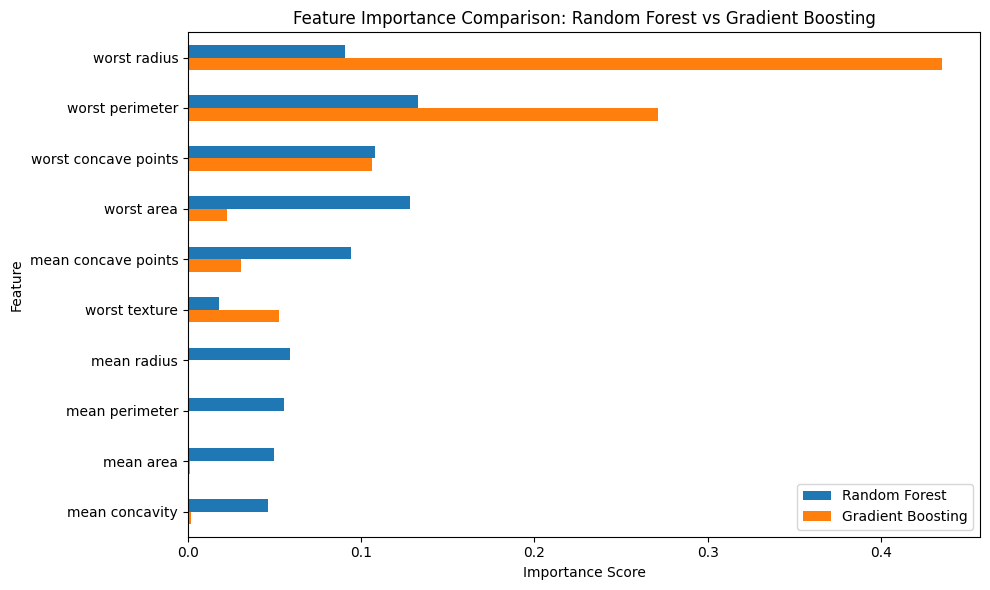

In [ ]:
# 9. Compare feature importances side by side

comparison = pd.DataFrame({
    "feature": X.columns,
    "Random Forest": rf_model.feature_importances_,
    "Gradient Boosting": gb_model.feature_importances_
})

comparison["average_importance"] = comparison[["Random Forest", "Gradient Boosting"]].mean(axis=1)

comparison_top = comparison.sort_values(
    by="average_importance",
    ascending=False
).head(10)

comparison_top = comparison_top.set_index("feature")

comparison_top[["Random Forest", "Gradient Boosting"]].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Feature Importance Comparison: Random Forest vs Gradient Boosting")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("figures/feature_importance_comparison.png", dpi=300)
plt.show()